# Backlog v2 — calibration, exposure and ensemble evidence

Read `docs/SPAN_002_PROTOCOL.md` and `docs/SPAN_002_RESULTS.md` for the predeclared
contract and decisions. This notebook reads current evidence and labels unfinished
work explicitly. Its existence does not establish span completion. All development
data have been inspected; confirmation is unused. Local log loss is not a new
official Kaggle score. Best official loss remains 0.97025 unless separately updated.


In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO=Path.cwd().resolve()
if not (REPO/'GOAL.md').exists(): REPO=REPO.parent
assert (REPO/'GOAL.md').exists()
RESULTS=REPO/'results/span_002'
HEAVY=Path.home()/'database/llm_classification_finetuning/runs/span_002'
FIGURES=HEAVY/'figures';FIGURES.mkdir(parents=True,exist_ok=True)
def read(name): return json.loads((RESULTS/name).read_text())
def save(fig,name):
    for extension in ['png','svg']:
        fig.savefig(FIGURES/(name+'.'+extension),bbox_inches='tight',dpi=160)
    plt.show()

plan=read('span_plan.json')
registry=json.loads((REPO/'backlog/hypotheses.json').read_text())
v2=next(v for v in registry['versions'] if v['number']==2)
records={item['id']:item for item in registry['items']}
display(pd.DataFrame([{'task':key,'title':records[key]['title'],'status':records[key]['status']}
                      for key in v2['focus_ids']]))
print('v2 state:',v2['state'],'original start:',plan['started_at'],'deadline:',plan['deadline'])
print('GPU cap:',plan['gpu_session_seconds_cap']/3600,'elapsed two-T4 session-hours')


,task,title,status
0,H40,Constrained probability calibration,done
1,E01,Instrument accepted optimizer updates and trai...,done
2,H03,Complete training exposure,running
3,H37,Diverse preference-model ensemble,running
4,H42,Preserve tie information during paired-order a...,done


v2 state: active original start: 2026-11-03T18:23:46+00:00 deadline: 2026-11-05T18:23:46+00:00
GPU cap: 12.0 elapsed two-T4 session-hours


## H40: small symmetric calibration

Five outer prompt-grouped folds; three grouped inner folds select among declared
families. The nested selector is primary. Each interval compares identical rows;
intervals condition on fitted OOF predictions and have no multiplicity guarantee.


,cohort,model,calibration,rows,log_loss,accuracy,tie_loss,tie_auc
0,full_baseline,frozen,temperature,5746,0.968872,0.527323,1.001286,0.667578
1,full_baseline,frozen,temperature_tie,5746,0.967179,0.531674,1.082651,0.667597
2,full_baseline,frozen,symmetric_vector,5746,0.967607,0.532196,1.082752,0.667507
3,full_baseline,frozen,nested_selected,5746,0.967740,0.532022,1.082821,0.667413
4,paired_pilot,frozen,temperature,1024,0.977479,0.522461,1.026904,0.659103
5,paired_pilot,frozen,temperature_tie,1024,0.976986,0.519531,1.074192,0.659041
6,paired_pilot,frozen,symmetric_vector,1024,0.977297,0.518555,1.073968,0.659664
7,paired_pilot,frozen,nested_selected,1024,0.976986,0.519531,1.074192,0.659041
8,paired_pilot,paired_ce,temperature,1024,0.978105,0.515625,1.152241,0.658131
9,paired_pilot,paired_ce,temperature_tie,1024,0.976984,0.517578,1.076027,0.657923


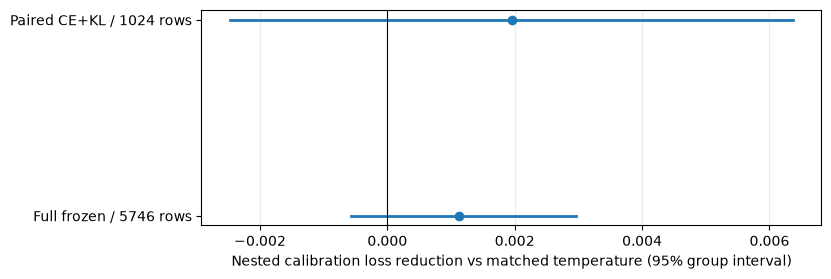

H42 practical stopping gate: {'overall_loss_gap': -0.00015099503594040442, 'tie_class_loss_gap': 0.0015366018961533445, 'calibration_resolves_deficit': True, 'interpretation': 'Predeclared practical stopping rule, not an equivalence test.'}
This gate does not prove equivalence or improved tie discrimination.


In [2]:
cal=read('calibration_results.json')
rows=[]
for cohort,entry in cal['cohorts'].items():
    for model,result in entry['models'].items():
        for family,metric in result['families'].items():
            rows.append({'cohort':cohort,'model':model,'calibration':family,
                         'rows':metric['rows'],'log_loss':metric['log_loss'],
                         'accuracy':metric['accuracy'],'tie_loss':metric['class_loss'][2],
                         'tie_auc':metric['tie_auc']})
display(pd.DataFrame(rows))
comparisons=[('Full frozen / 5746 rows',cal['cohorts']['full_baseline']['models']['frozen']['nested_gain_vs_temperature']),
             ('Paired CE+KL / 1024 rows',cal['cohorts']['paired_pilot']['models']['paired_kl']['nested_gain_vs_temperature'])]
fig,ax=plt.subplots(figsize=(8,2.8))
for index,(label,result) in enumerate(comparisons):
    lo,hi=result['interval_95']
    ax.plot([lo,hi],[index,index],color='C0',linewidth=2)
    ax.scatter([result['gain']],[index],color='C0',zorder=3)
ax.set_yticks(range(len(comparisons)),[label for label,_ in comparisons])
ax.axvline(0,color='black',linewidth=.8);ax.grid(axis='x',alpha=.25)
ax.set_xlabel('Nested calibration loss reduction vs matched temperature (95% group interval)')
save(fig,'calibration_gains')
print('H42 practical stopping gate:',cal['cohorts']['paired_pilot']['h42_gate'])
print('This gate does not prove equivalence or improved tie discrimination.')


## H37: complementary predictions

The classifier and Gemma judge are individually calibrated inside training folds;
a single blend weight is chosen using inner OOF predictions. Larger validation,
when present, uses fixed extra IDs and a separately frozen cached-data recipe.
Report both quality and runtime: useful complementarity alone does not prove a
deployable hidden-test ensemble.


,system,rows,log_loss,accuracy,tie_loss
0,classifier,512,0.991976,0.515625,1.009526
1,judge,512,1.002209,0.507812,1.135440
2,blend,512,0.972668,0.542969,1.049299


Cached outer-fold judge weights: [0.3584, 0.444, 0.5712, 0.3832, 0.4921]
Uniform current-runtime validation is pending; historical judge outputs will not be pooled with new outputs.


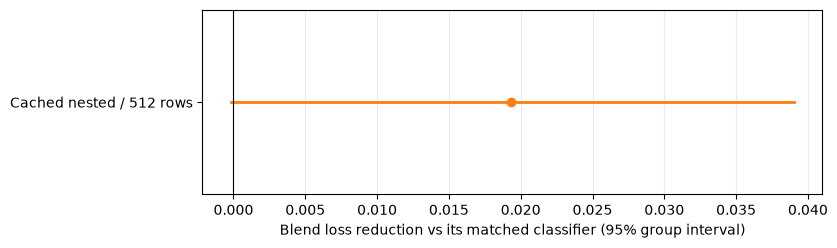

Native CUDA devices before repair: Available devices:
  (none)

Native CUDA devices after repair: Available devices:
  CUDA0: Tesla T4 (14911 MiB, 14806 MiB free)
  CUDA1: Tesla T4 (14911 MiB, 14806 MiB free)

Historical-cache identity/runtime gate: {'profile_rows': 32, 'profile_seconds': 38.65186396199999, 'mean_probability_difference': 0.021964193310207335, 'max_probability_difference': 0.16802273048218563, 'mean_limit': 0.01, 'max_limit': 0.1, 'projected_extra_seconds_with_margin': 2826.3473642111994, 'remaining_session_seconds': 4201.758108139038, 'identity_passed': False, 'throughput_passed': True}
The failed identity gate stopped scoring; the separate full cohort is re-scored uniformly.


In [3]:
cached=read('blend_results.json')['cohorts']['cached_judge']
display(pd.DataFrame([{'system':name,'rows':m['rows'],'log_loss':m['log_loss'],'accuracy':m['accuracy'],
                      'tie_loss':m['class_loss'][2]} for name,m in cached['models'].items()]))
print('Cached outer-fold judge weights:',[round(x['judge_weight'],4) for x in cached['folds']])
points=[('Cached nested / 512 rows',cached['blend_gain_vs_classifier'])]
if (RESULTS/'expanded_results.json').exists():
    expanded=read('expanded_results.json')
    for cohort,row in expanded['cohorts'].items():
        print(cohort)
        display(pd.DataFrame([{'system':name,'rows':m['rows'],'log_loss':m['log_loss'],
                              'accuracy':m['accuracy'],'tie_loss':m['class_loss'][2]}
                             for name,m in row['models'].items()]))
        points.append((cohort+' / '+str(row['rows'])+' rows',row['contrasts']['blend']))
    print('Runtime assessment:',expanded['runtime'])
else:
    print('Uniform current-runtime validation is pending; historical judge outputs will not be pooled with new outputs.')
fig,ax=plt.subplots(figsize=(8,max(2.4,.8*len(points))))
for index,(label,result) in enumerate(points):
    lo,hi=result['interval_95']
    ax.plot([lo,hi],[index,index],linewidth=2,color='C1')
    ax.scatter(result['gain'],index,color='C1',zorder=3)
ax.set_yticks(range(len(points)),[label for label,_ in points])
ax.axvline(0,color='black',linewidth=.8);ax.grid(axis='x',alpha=.25)
ax.set_xlabel('Blend loss reduction vs its matched classifier (95% group interval)')
save(fig,'ensemble_gains')
if (RESULTS/'runtime_diagnostic_results.json').exists():
    runtime=read('runtime_diagnostic_results.json')
    print('Native CUDA devices before repair:',runtime['hardware']['devices_before'])
    print('Native CUDA devices after repair:',runtime['hardware']['devices_after'])
    print('Historical-cache identity/runtime gate:',runtime['gate'])
    print('The failed identity gate stopped scoring; the separate full cohort is re-scored uniformly.')


## E01 and H42: verified measurement and a stopped conditional experiment

The actual CUDA probe compares parameter changes with optimizer skip flags and
resumes checkpointed counters, scaler and scheduler. It uses a tiny deterministic
dataset; it does not prove bitwise reproduction of every stochastic training
pipeline. H42 stopped at its declared calibration gate without anchor training.


In [4]:
probe=read('instrumentation_results.json')
assert probe['passed']
display(pd.DataFrame([{'rank':rank['rank'],'run':run['name'],**run['counts']}
                      for rank in probe['ranks'] for run in rank['runs']]))
print('Actual CUDA software:',probe['software'])
print('Probe session:',probe['session_summary'])
print('Original training was cu128; this runtime is cu130. H03 is stateful continuation, without bitwise-equivalence claims.')
print('H42 calibration gate passed:',cal['cohorts']['paired_pilot']['h42_gate']['calibration_resolves_deficit'])


,rank,run,cycles,accepted_updates,skipped_updates,processed_tokens,accepted_tokens,processed_rows,accepted_rows,processed_unique_rows,accepted_unique_rows,processed_class_counts,accepted_class_counts,last_global_step
0,0,continuous,5,4,1,80,64,20,16,20,16,"[8, 8, 4]","[7, 6, 3]",5
1,0,resumed,5,4,1,80,64,20,16,20,16,"[8, 8, 4]","[7, 6, 3]",5
2,1,continuous,5,4,1,80,64,20,16,20,16,"[6, 6, 8]","[5, 5, 6]",5
3,1,resumed,5,4,1,80,64,20,16,20,16,"[6, 6, 8]","[5, 5, 6]",5


Actual CUDA software: {'torch': '2.11.0+cu130', 'transformers': '5.22.1', 'accelerate': '1.15.0', 'peft': '0.21.2'}
Probe session: {'exit_code': 0, 'session_seconds': 55.01853656768799}
Original training was cu128; this runtime is cu130. H03 is stateful continuation, without bitwise-equivalence claims.
H42 calibration gate passed: True


## H03: stateful training exposure

Continue selected checkpoint 800 toward the original one-epoch endpoint. Report
new accepted exposure separately from unknown historical accepted exposure. Fixed
final model is primary; training minibatch loss, selection loss and final calibrated
development loss have different data/postprocessing and must not be conflated.


In [5]:
if (RESULTS/'exposure_results.json').exists():
    training=read('exposure_results.json')
    display(pd.DataFrame([{'calibration':family,'system':name,'rows':m['rows'],
                          'log_loss':m['log_loss'],'accuracy':m['accuracy'],'tie_auc':m['tie_auc']}
                         for family,row in training['cohorts'].items() for name,m in row['models'].items()]))
    display(pd.DataFrame(training['exposure']['rank_summaries']))
    print('Coverage:',training['exposure']['coverage'])
    print('Training result:',{k:training['summary'][k] for k in ['initial_step','final_step','epochs_completed',
                              'training_seconds','development_prediction_seconds','stopped_for_time','stopped_for_plateau']})
    print('Identity guards:',training['starting_identity'])
    print('Finite exported weights:',training['weight_audit'])
    progress_path=HEAVY/'jobs/exposure/output/exposure/training_progress.jsonl'
    progress=[json.loads(line) for line in progress_path.read_text().splitlines()]
    train=[x for x in progress if 'loss' in x];validation=[x for x in progress if 'eval_log_loss' in x]
    fig,ax=plt.subplots(figsize=(8,3.5))
    ax.plot([x['step'] for x in train],[x['loss'] for x in train],alpha=.6,label='Training minibatch CE')
    if validation:
        ax.plot([x['step'] for x in validation],[x['eval_log_loss'] for x in validation],'o-',label='Original-order selection loss')
    ax.set_xlabel('Nominal Trainer step (not accepted-update count)');ax.set_ylabel('Uncalibrated log loss')
    ax.legend();ax.grid(alpha=.25);save(fig,'training_curve')
else:
    snapshot=RESULTS/'live_progress_exposure.json'
    print('Final H03 quality is pending.')
    if snapshot.exists():display(json.loads(snapshot.read_text()))


Final H03 quality is pending.


{'job': 'exposure',
 'kernel': 'arseniytrushin/llm-preference-span-002-exposure',
 'version': 1,
 'status': 'KernelWorkerStatus.RUNNING',
 'status_observed_at': '2026-11-03T20:38:16.390457+00:00',
 'log_reader_exit_code': 0,
 'log_snapshot_mtime': '2026-11-03T20:38:34.899790+00:00',
 'last_snapshot_phase': 'training_logs_available',
 'JOINT_PROGRESS': {'step': 1060,
  'elapsed_seconds': 5971.0214469719995,
  'loss': 0.99461669921875,
  'grad_norm': 29.364830017089844,
  'learning_rate': 9.075027282808618e-06,
  'epoch': 0.7375195686206297},
 'new_log_events_received': True,
 'log_reader_notice': "ConnectionError: HTTPSConnectionPool(host='api.kaggle.com', port=443): Read timed out.",
 'original_selection_reference': {'step': 800,
  'raw_original_order_log_loss': 0.9787039158366522,
  'rows': 1024,
  'note': 'Original fixed selection sample; distinct from swap-averaged calibrated final dev loss.'},
 'validation_history': {'1000': {'step': 1000,
   'elapsed_seconds': 4566.096514966,
   '

## Resources and versioned handoff

Completion requires actual finished/stopped jobs, final evidence, this executed
notebook and sealed v2/v3 snapshots. Read the final report and audit; a green
notebook or a successful pilot is insufficient by itself.


In [6]:
audit_path=RESULTS/'terminal_audit.json'
if audit_path.exists():
    display(json.loads(audit_path.read_text()))
else:
    print('Terminal resource audit pending; goal remains active.')
display(pd.DataFrame([{'version':v['number'],'state':v['state'],'members':len(v['item_ids']),
                      'focus':v['focus_ids']} for v in registry['versions']]))
print('Standalone figures:',FIGURES)


Terminal resource audit pending; goal remains active.

,version,state,members,focus
0,1,closed,41,"[E00, H01, H09, H04, H11]"
1,2,active,39,"[H40, E01, H03, H37, H42]"
2,3,draft,2,[]


Standalone figures: /home/tarstars/database/llm_classification_finetuning/runs/span_002/figures
